# 서울시 전월세 실거래 API 지역 비교

이 노트북은 서울 열린데이터광장의 전월세 실거래 API를 호출하고, 월세를 전세 환산보증금으로 바꿔 지역별로 비교합니다. 분석 코드와 실행 순서는 이 파일에 저장되어 있습니다.

- 자료: 서울시 전월세 실거래 정보 API, 서비스명 tbLnOpendataRentV
- API 자료 범위: 최근 3개 신고 접수연도
- 기본 비교: 선택한 자치구의 법정동별 전용면적 1㎡당 전세 환산보증금 중앙값
- 환산 기준: 전세 환산보증금 = 보증금 + 월세 × 12 ÷ 전환율
- 기본 전환율: 연 5.0%이며 설정 셀에서 바꿀 수 있습니다.
- API 키는 lecture04_spatial_data_analysis/.env에서 읽고 화면에 출력하지 않습니다.
- API 연결은 HTTP로 확인되어, 키가 Worker에서 API 제공처로 전송되는 구간은 암호화되지 않습니다. 이 조건을 확인하고 진행하기로 한 작업입니다.

처음 실행할 때 API 페이지를 수집하고 압축 캐시를 저장합니다. 같은 연도와 지역을 다시 실행하면 캐시를 사용합니다. 자료를 갱신하려면 설정 셀에서 REFRESH_API_CACHE를 True로 바꾸세요.

In [1]:
from pathlib import Path
from datetime import date, datetime
import json
import math
import os
import time

import pandas as pd
import requests
from IPython.display import display

def find_course_dir():
    candidates = [Path.cwd(), *Path.cwd().parents]
    for candidate in candidates:
        if candidate.name == "lecture04_spatial_data_analysis" and (candidate / ".env").is_file():
            return candidate
        fallback = candidate / "강의자료" / "lecture04_spatial_data_analysis"
        if (fallback / ".env").is_file():
            return fallback
    raise FileNotFoundError("lecture04_spatial_data_analysis/.env 파일을 찾지 못했습니다.")

COURSE_DIR = find_course_dir()
APP_DIR = COURSE_DIR / "assignment2_seoul_rent"
CACHE_DIR = APP_DIR / "data" / "api_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

def read_seoul_api_key():
    if os.environ.get("SEOUL_API_KEY"):
        return os.environ["SEOUL_API_KEY"].strip()
    env_path = COURSE_DIR / ".env"
    for line in env_path.read_text(encoding="utf-8").splitlines():
        if line.strip().startswith("SEOUL_API_KEY="):
            value = line.split("=", 1)[1].strip().strip('"').strip("'")
            if value:
                os.environ["SEOUL_API_KEY"] = value
                return value
    raise RuntimeError("lecture04_spatial_data_analysis/.env에 SEOUL_API_KEY가 없습니다.")

SEOUL_API_KEY = read_seoul_api_key()
CURRENT_YEAR = date.today().year
RECEIPT_YEAR = CURRENT_YEAR
GU_CODE = "11680"  # 서울 전체를 수집하려면 "ALL"로 변경
GU_NAME = "강남구"
MONTHLY_CONVERSION_RATE = 5.0  # 연 전환율, 퍼센트
REFRESH_API_CACHE = False
PAGE_SIZE = 1000
PAGE_PAUSE_SECONDS = 0.15

GU_NAMES = {
    "11110": "종로구", "11140": "중구", "11170": "용산구", "11200": "성동구",
    "11215": "광진구", "11230": "동대문구", "11260": "중랑구", "11290": "성북구",
    "11305": "강북구", "11320": "도봉구", "11350": "노원구", "11380": "은평구",
    "11410": "서대문구", "11440": "마포구", "11470": "양천구", "11500": "강서구",
    "11530": "구로구", "11545": "금천구", "11560": "영등포구", "11590": "동작구",
    "11620": "관악구", "11650": "서초구", "11680": "강남구", "11710": "송파구",
    "11740": "강동구"
}
if GU_CODE != "ALL":
    GU_NAME = GU_NAMES[GU_CODE]

print("API 키 설정:", bool(SEOUL_API_KEY))
print("조회 조건:", RECEIPT_YEAR, "년,", "서울 전체" if GU_CODE == "ALL" else GU_NAME)
print("같은 조건의 캐시가 있으면 재사용합니다.")

API 키 설정: True
조회 조건: 2026 년, 강남구
같은 조건의 캐시가 있으면 재사용합니다.


In [2]:
API_ROOT = "http://openapi.seoul.go.kr:8088"
SERVICE_NAME = "tbLnOpendataRentV"
SESSION = requests.Session()

def fetch_api_page(start, end, receipt_year, gu_code, gu_name):
    url = (
        API_ROOT + "/" + SEOUL_API_KEY + "/json/" + SERVICE_NAME + "/" +
        str(start) + "/" + str(end) + "/" + str(receipt_year) + "/"
    )
    if gu_code != "ALL":
        from urllib.parse import quote
        url += str(gu_code) + "/" + quote(gu_name) + "/"
    try:
        response = SESSION.get(url, timeout=45)
        if not response.ok:
            raise RuntimeError("서울시 API가 HTTP 오류를 반환했습니다.")
        payload = response.json()
    except Exception:
        # 예외 메시지에 API URL이 들어갈 수 있어 원문을 다시 출력하지 않습니다.
        raise RuntimeError("서울시 API 요청 또는 응답 처리에 실패했습니다.") from None

    block = payload.get(SERVICE_NAME, {})
    result = block.get("RESULT", {})
    rows = block.get("row", [])
    total_count = int(block.get("list_total_count", 0) or 0)
    if not rows and result.get("CODE") == "INFO-200":
        return [], total_count
    if not rows and result.get("CODE"):
        raise RuntimeError("서울시 API 오류 코드: " + str(result.get("CODE")))
    return rows or [], total_count

def cache_file(receipt_year, gu_code):
    safe_region = "all" if gu_code == "ALL" else str(gu_code)
    return CACHE_DIR / ("rent_" + str(receipt_year) + "_" + safe_region + ".csv.gz")

def fetch_selected_data(receipt_year, gu_code, gu_name, refresh=False):
    target = cache_file(receipt_year, gu_code)
    metadata_path = target.with_name(target.name + ".meta.json")
    if target.is_file() and not refresh:
        cached = pd.read_csv(target, compression="gzip")
        if metadata_path.is_file():
            metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
            collected_at = metadata.get("collected_at", "확인 필요")
        else:
            collected_at = "기존 캐시라 수집일 메타데이터 없음"
        print("압축 캐시를 사용합니다:", len(cached), "건 · API 수집일:", collected_at)
        return cached

    first_rows, total_count = fetch_api_page(1, PAGE_SIZE, receipt_year, gu_code, gu_name)
    if total_count <= 0 and first_rows:
        total_count = len(first_rows)
    pages = math.ceil(total_count / PAGE_SIZE) if total_count else (1 if first_rows else 0)
    all_rows = list(first_rows)
    print("예상 페이지:", pages, "· 전체 API 거래:", f"{total_count:,}건")

    for page_number in range(1, pages):
        start = page_number * PAGE_SIZE + 1
        end = start + PAGE_SIZE - 1
        page_rows, _ = fetch_api_page(start, end, receipt_year, gu_code, gu_name)
        all_rows.extend(page_rows)
        print(f"{page_number + 1}/{pages} 페이지 · {len(all_rows):,}/{total_count:,}건")
        if PAGE_PAUSE_SECONDS:
            time.sleep(PAGE_PAUSE_SECONDS)

    if not all_rows:
        raise RuntimeError("선택한 조건에 해당하는 거래가 없습니다.")

    result = pd.DataFrame(all_rows)
    result.to_csv(target, index=False, compression="gzip", encoding="utf-8")
    metadata = {
        "source": "서울 열린데이터광장 tbLnOpendataRentV",
        "source_page": "https://data.seoul.go.kr/dataList/OA-21276/S/1/datasetView.do?tab=A",
        "receipt_year": receipt_year,
        "region": "서울 전체" if gu_code == "ALL" else gu_name,
        "row_count": len(result),
        "collected_at": datetime.now().astimezone().isoformat(timespec="seconds")
    }
    metadata_path.write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
    print("수집 완료 · 압축 캐시 저장:", target.name)
    print("자료 출처:", metadata["source"])
    print("API 수집일:", metadata["collected_at"])
    return result

api_raw = fetch_selected_data(
    RECEIPT_YEAR, GU_CODE, GU_NAME, refresh=REFRESH_API_CACHE
)
print("API 응답 행:", f"{len(api_raw):,}")

예상 페이지: 29 · 전체 API 거래: 28,213건
2/29 페이지 · 2,000/28,213건
3/29 페이지 · 3,000/28,213건
4/29 페이지 · 4,000/28,213건
5/29 페이지 · 5,000/28,213건
6/29 페이지 · 6,000/28,213건
7/29 페이지 · 7,000/28,213건
8/29 페이지 · 8,000/28,213건
9/29 페이지 · 9,000/28,213건
10/29 페이지 · 10,000/28,213건
11/29 페이지 · 11,000/28,213건
12/29 페이지 · 12,000/28,213건
13/29 페이지 · 13,000/28,213건
14/29 페이지 · 14,000/28,213건
15/29 페이지 · 15,000/28,213건
16/29 페이지 · 16,000/28,213건
17/29 페이지 · 17,000/28,213건
18/29 페이지 · 18,000/28,213건
19/29 페이지 · 19,000/28,213건
20/29 페이지 · 20,000/28,213건
21/29 페이지 · 21,000/28,213건
22/29 페이지 · 22,000/28,213건
23/29 페이지 · 23,000/28,213건
24/29 페이지 · 24,000/28,213건
25/29 페이지 · 25,000/28,213건
26/29 페이지 · 26,000/28,213건
27/29 페이지 · 27,000/28,213건
28/29 페이지 · 28,000/28,213건
29/29 페이지 · 28,213/28,213건
수집 완료 · 압축 캐시 저장: rent_2026_11680.csv.gz
자료 출처: 서울 열린데이터광장 tbLnOpendataRentV
API 수집일: 2026-10-17T16:20:27+09:00
API 응답 행: 28,213


In [3]:
FIELD_ALIASES = {
    "gu": ["CGG_NM", "SIGUNGU_NM"],
    "dong": ["STDG_NM", "LEGAL_DONG_NM"],
    "contract_day": ["CTRT_DAY", "CTRCT_DAY", "CNTRCT_DE"],
    "rent_type": ["RENT_SE", "RENT_TYPE"],
    "area": ["RENT_AREA", "AREA"],
    "deposit": ["GRFE", "DEPOSIT"],
    "monthly_rent": ["RTFE", "MONTHLY_RENT"],
    "building_use": ["BLDG_USG", "BUILDING_USE"]
}

def first_available(row, aliases):
    for name in aliases:
        if name in row:
            return row[name]
    return None

def numeric_series(series):
    return pd.to_numeric(
        series.astype(str).str.replace(",", "", regex=False).str.strip(),
        errors="coerce"
    )

records = []
for row in api_raw.to_dict("records"):
    records.append({
        name: first_available(row, aliases)
        for name, aliases in FIELD_ALIASES.items()
    })

rent = pd.DataFrame(records)
for column in ["area", "deposit", "monthly_rent"]:
    rent[column] = numeric_series(rent[column]).fillna(0)

rent["gu"] = rent["gu"].fillna("").astype(str).str.strip()
rent["dong"] = rent["dong"].fillna("").astype(str).str.strip()
rent["rent_type"] = rent["rent_type"].fillna("").astype(str).str.strip()
rent["building_use"] = rent["building_use"].fillna("").astype(str).str.strip()
rent["contract_day"] = rent["contract_day"].fillna("").astype(str).str.replace(r"\.0$", "", regex=True)
rent["contract_date"] = pd.to_datetime(rent["contract_day"], format="%Y%m%d", errors="coerce")

rate_decimal = MONTHLY_CONVERSION_RATE / 100
if rate_decimal <= 0:
    raise ValueError("월세 전환율은 0보다 커야 합니다.")

is_monthly = rent["rent_type"].str.contains("월세", na=False)
rent["equivalent_deposit"] = rent["deposit"] + (
    rent["monthly_rent"].where(is_monthly, 0) * 12 / rate_decimal
)
rent["equivalent_deposit_per_m2"] = (
    rent["equivalent_deposit"] / rent["area"].where(rent["area"] > 0)
)
rent = rent.replace([float("inf"), -float("inf")], pd.NA)
rent = rent.dropna(subset=["equivalent_deposit_per_m2"])
rent = rent[rent["equivalent_deposit_per_m2"] > 0].copy()
rent["region"] = (rent["gu"].str.strip() + " " + rent["dong"].str.strip()).str.strip()
rent["region"] = rent["region"].replace("", "법정동 미상")
rent["contract_month"] = rent["contract_date"].dt.to_period("M").astype("string")

print("분석 가능 거래:", f"{len(rent):,}건")
print("건물 용도:", ", ".join(sorted(value for value in rent["building_use"].unique() if value)))
display(rent.head(5))

분석 가능 거래: 28,213건
건물 용도: 단독다가구, 아파트, 연립다세대, 오피스텔


,gu,dong,contract_day,rent_type,area,deposit,monthly_rent,building_use,contract_date,equivalent_deposit,equivalent_deposit_per_m2,region,contract_month
0,강남구,자곡동,20261015,전세,101.940,115000,0,아파트,2026-10-15,115000.0,1128.114577,강남구 자곡동,2026-10
1,강남구,논현동,20261015,전세,76.120,60000,0,연립다세대,2026-10-15,60000.0,788.229112,강남구 논현동,2026-10
2,강남구,역삼동,20261015,전세,59.780,130000,0,아파트,2026-10-15,130000.0,2174.640348,강남구 역삼동,2026-10
3,강남구,도곡동,20261015,전세,84.890,135000,0,아파트,2026-10-15,135000.0,1590.293321,강남구 도곡동,2026-10
4,강남구,일원동,20261015,월세,46.855,24853,57,아파트,2026-10-15,38533.0,822.388219,강남구 일원동,2026-10


선택 건물 용도: 전체
비교 지역 수: 14


,region,거래건수,환산보증금_만원_per_m2,환산보증금_만원,전용면적_m2
0,강남구 도곡동,1838,1109.419807,89800.0,84.740
1,강남구 청담동,1211,1094.246382,68400.0,59.400
2,강남구 삼성동,2083,1063.659629,55650.0,59.670
3,강남구 수서동,874,1012.401924,45940.0,49.200
4,강남구 개포동,3040,1011.889704,48500.0,54.310
5,강남구 역삼동,6011,965.250965,27400.0,30.780
6,강남구 압구정동,745,964.932925,92400.0,107.640
7,강남구 일원동,1856,950.630685,43600.0,59.750
8,강남구 대치동,3661,917.034346,58000.0,59.997
9,강남구 논현동,3048,808.924647,27200.0,33.860


,contract_month,환산보증금_만원_per_m2,거래건수
0,2025-11,1000.533333,95
1,2025-12,955.700799,1069
2,2026-01,930.735931,3557
3,2026-02,926.797745,2878
4,2026-03,891.745450,3292
5,2026-04,917.863027,2917
6,2026-05,894.318510,3194
7,2026-06,860.250908,3260
8,2026-07,937.622086,2699
9,2026-08,953.440278,2412


공간 조인 전 경계 행: 25 · 조인 후: 25 · 매칭 자치구: 1


/var/folders/mt/8zz5g8ln4kl9pgfg5pl17p3c0000gn/T/ipykernel_79850/1544035374.py:67: UserWarning: Glyph 51088 (\N{HANGUL SYLLABLE JA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/mt/8zz5g8ln4kl9pgfg5pl17p3c0000gn/T/ipykernel_79850/1544035374.py:67: UserWarning: Glyph 52824 (\N{HANGUL SYLLABLE CI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/mt/8zz5g8ln4kl9pgfg5pl17p3c0000gn/T/ipykernel_79850/1544035374.py:67: UserWarning: Glyph 44396 (\N{HANGUL SYLLABLE GU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/mt/8zz5g8ln4kl9pgfg5pl17p3c0000gn/T/ipykernel_79850/1544035374.py:67: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/mt/8zz5g8ln4kl9pgfg5pl17p3c0000gn/T/ipykernel_79850/1544035374.py:67: UserWarning: Glyph 51204 (\N{HANGUL SYLLABLE JEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/mt/8zz5g8ln4kl9pgfg5pl17p3c0000gn/T/ipyker

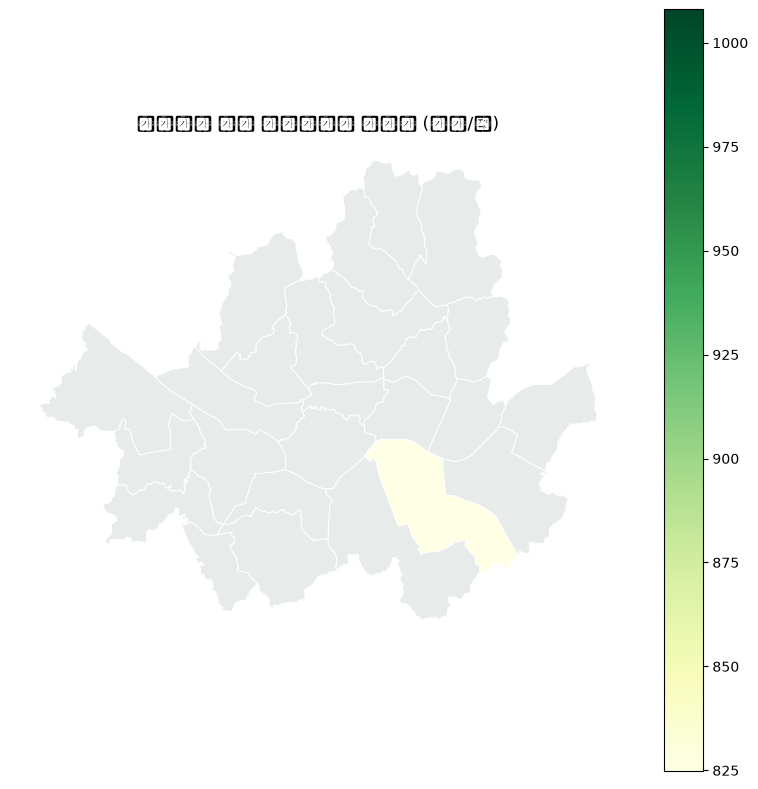

/var/folders/mt/8zz5g8ln4kl9pgfg5pl17p3c0000gn/T/ipykernel_79850/1544035374.py:82: UserWarning: Glyph 47564 (\N{HANGUL SYLLABLE MAN}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/var/folders/mt/8zz5g8ln4kl9pgfg5pl17p3c0000gn/T/ipykernel_79850/1544035374.py:82: UserWarning: Glyph 50896 (\N{HANGUL SYLLABLE WEON}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/var/folders/mt/8zz5g8ln4kl9pgfg5pl17p3c0000gn/T/ipykernel_79850/1544035374.py:82: UserWarning: Glyph 13217 (\N{SQUARE M SQUARED}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/var/folders/mt/8zz5g8ln4kl9pgfg5pl17p3c0000gn/T/ipykernel_79850/1544035374.py:82: UserWarning: Glyph 44053 (\N{HANGUL SYLLABLE GANG}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/var/folders/mt/8zz5g8ln4kl9pgfg5pl17p3c0000gn/T/ipykernel_79850/1544035374.py:82: UserWarning: Glyph 45224 (\N{HANGUL SYLLABLE NAM}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/var/folders/mt/8zz5g8ln4kl9pgfg5pl17p3c0000gn/T/ipykern

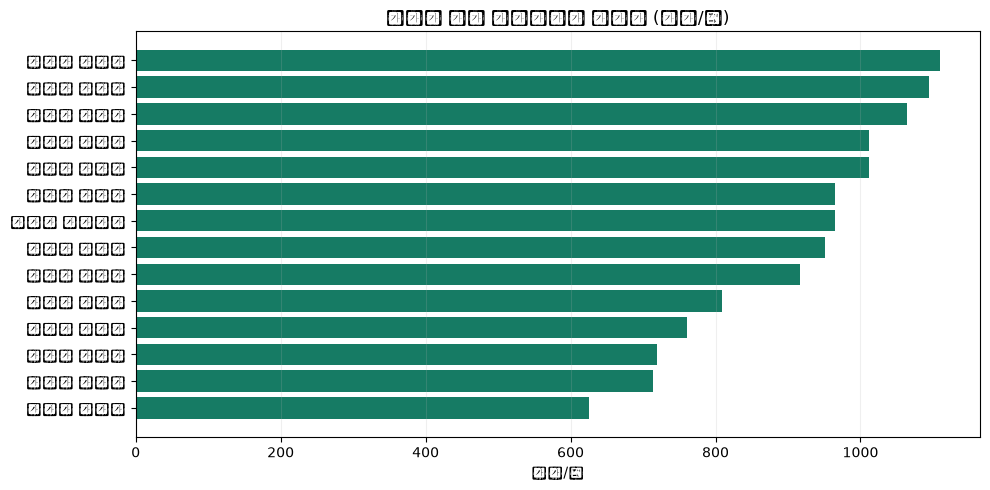

/var/folders/mt/8zz5g8ln4kl9pgfg5pl17p3c0000gn/T/ipykernel_79850/1544035374.py:93: UserWarning: Glyph 47564 (\N{HANGUL SYLLABLE MAN}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/var/folders/mt/8zz5g8ln4kl9pgfg5pl17p3c0000gn/T/ipykernel_79850/1544035374.py:93: UserWarning: Glyph 50896 (\N{HANGUL SYLLABLE WEON}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/var/folders/mt/8zz5g8ln4kl9pgfg5pl17p3c0000gn/T/ipykernel_79850/1544035374.py:93: UserWarning: Glyph 13217 (\N{SQUARE M SQUARED}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/var/folders/mt/8zz5g8ln4kl9pgfg5pl17p3c0000gn/T/ipykernel_79850/1544035374.py:93: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/var/folders/mt/8zz5g8ln4kl9pgfg5pl17p3c0000gn/T/ipykernel_79850/1544035374.py:93: UserWarning: Glyph 51228 (\N{HANGUL SYLLABLE JE}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/var/folders/mt/8zz5g8ln4kl9pgfg5pl17p3c0000gn/T/ipykernel

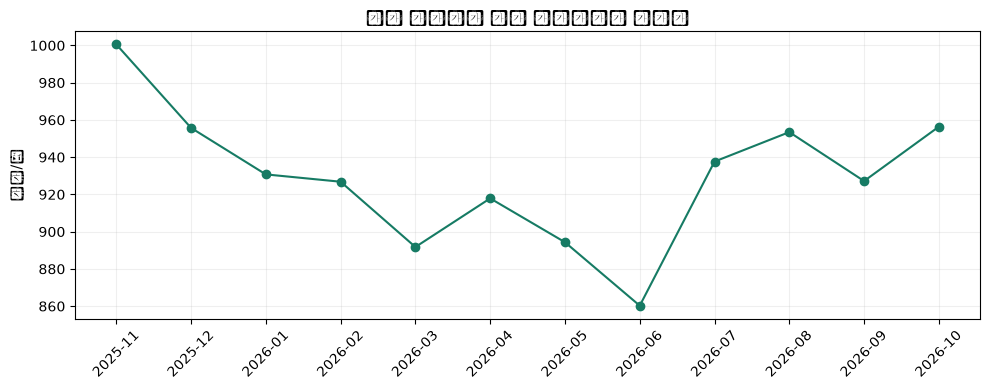

In [4]:
BUILDING_USE = "전체"  # 예: "아파트", "연립다세대", "단독다가구", "오피스텔"
analysis = rent.copy()
if BUILDING_USE != "전체":
    analysis = analysis[analysis["building_use"] == BUILDING_USE]

by_region = (
    analysis.groupby("region", dropna=False)
    .agg(
        거래건수=("equivalent_deposit_per_m2", "size"),
        환산보증금_만원_per_m2=("equivalent_deposit_per_m2", "median"),
        환산보증금_만원=("equivalent_deposit", "median"),
        전용면적_m2=("area", "median")
    )
    .sort_values("환산보증금_만원_per_m2", ascending=False)
    .reset_index()
)

by_month = (
    analysis.dropna(subset=["contract_month"])
    .groupby("contract_month")["equivalent_deposit_per_m2"]
    .agg(["median", "size"])
    .rename(columns={"median": "환산보증금_만원_per_m2", "size": "거래건수"})
    .reset_index()
)

print("선택 건물 용도:", BUILDING_USE)
print("비교 지역 수:", len(by_region))
display(by_region.head(20))
display(by_month)

try:
    import geopandas as gpd
    import matplotlib.pyplot as plt

    boundary_path = COURSE_DIR / "data" / "seoul_adm_sigungu_2025Q2.geojson"
    boundaries = gpd.read_file(boundary_path)
    boundaries["SIGUNGU_NM"] = boundaries["SIGUNGU_NM"].astype(str).str.strip()
    gu_summary = analysis.groupby("gu", dropna=False).agg(
        환산보증금_만원_per_m2=("equivalent_deposit_per_m2", "median"),
        거래건수=("equivalent_deposit_per_m2", "size")
    ).reset_index()
    gu_summary["gu"] = gu_summary["gu"].astype(str).str.strip()
    if boundaries["SIGUNGU_NM"].duplicated().any():
        raise ValueError("자치구 경계 이름이 중복되어 공간 조인을 중단합니다.")
    if gu_summary["gu"].duplicated().any():
        raise ValueError("거래 자료 자치구 이름이 중복되어 공간 조인을 중단합니다.")

    boundary_rows_before = len(boundaries)
    spatial_result = boundaries.merge(
        gu_summary, left_on="SIGUNGU_NM", right_on="gu", how="left", validate="one_to_one"
    )
    matched_gu = int(spatial_result["환산보증금_만원_per_m2"].notna().sum())
    print("공간 조인 전 경계 행:", boundary_rows_before,
          "· 조인 후:", len(spatial_result), "· 매칭 자치구:", matched_gu)

    ax = spatial_result.plot(
        column="환산보증금_만원_per_m2",
        cmap="YlGn",
        legend=True,
        edgecolor="white",
        linewidth=0.7,
        missing_kwds={"color": "#e7ecea", "label": "거래 자료 없음"},
        figsize=(8, 8)
    )
    ax.set_axis_off()
    ax.set_title("자치구별 전세 환산보증금 중앙값 (만원/㎡)")
    plt.tight_layout()
    display(ax.figure)
    plt.close(ax.figure)
except ImportError:
    print("GeoPandas 또는 matplotlib이 설치되어 있지 않아 지도는 생략했습니다.")

try:
    import matplotlib.pyplot as plt
    from IPython.display import display as display_image
    top_regions = by_region.head(20).sort_values("환산보증금_만원_per_m2")
    fig, ax = plt.subplots(figsize=(10, max(5, len(top_regions) * 0.28)))
    ax.barh(top_regions["region"], top_regions["환산보증금_만원_per_m2"], color="#167b64")
    ax.set_title("지역별 전세 환산보증금 중앙값 (만원/㎡)")
    ax.set_xlabel("만원/㎡")
    ax.grid(axis="x", alpha=0.2)
    fig.tight_layout()
    display(fig)
    plt.close(fig)

    if not by_month.empty:
        fig, ax = plt.subplots(figsize=(10, 4))
        ax.plot(by_month["contract_month"].astype(str), by_month["환산보증금_만원_per_m2"], marker="o", color="#167b64")
        ax.set_title("실제 계약월별 전세 환산보증금 중앙값")
        ax.set_ylabel("만원/㎡")
        ax.tick_params(axis="x", rotation=45)
        ax.grid(alpha=0.2)
        fig.tight_layout()
        display(fig)
        plt.close(fig)
except ImportError:
    print("matplotlib이 설치되어 있지 않아 표만 표시했습니다.")

## 해석 시 주의할 점

이 결과는 실제 계약 신고 자료의 중앙값이며, 매물 호가나 현재 시장의 전체 가격을 뜻하지 않습니다. 면적, 건물 용도, 거래 시점에 따라 구성 차이가 있으므로 동일한 건물 용도와 기간으로 다시 비교할 수 있습니다. 월세 환산율은 분석 가정이므로 4%, 5%, 6%처럼 바꿔 민감도를 확인하세요.

이 노트북은 법정동 이름으로 비교합니다. 강의 경계자료는 행정동 기준일 수 있어 법정동과 행정동을 같은 코드처럼 결합하지 않습니다. API 자료 출처는 서울 열린데이터광장 전월세 실거래 정보이며, 수집일은 노트북 실행일입니다.

API 최신값을 다시 수집하려면 설정 셀에서 REFRESH_API_CACHE를 True로 바꾸고 API 수집 셀부터 다시 실행하세요. 서울 전체 자료를 조회하려면 GU_CODE를 ALL로 설정할 수 있으며, 다수의 페이지 요청이 발생합니다.